In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/loan_applications.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLoan status distribution:")
print(df["Loan_Status"].value_counts(dropna=False))


print("Categorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nUnique values in Loan_Status:")
print(df["Loan_Status"].unique())

print("\nUnique values in Credit_History:")
print(df["Credit_History"].value_counts(dropna=False))

Dataset shape: (500, 13)

First 5 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP100001,Male,No,1,Graduate,No,2858,0,446.0,360,1.0,Rural,N
1,LP100002,Male,No,1,Graduate,Yes,7229,0,600.0,360,1.0,Rural,Y
2,LP100003,Female,No,1,Graduate,No,2624,0,436.0,360,1.0,Semiurban,Y
3,LP100004,Male,Yes,0,Graduate,No,4074,457,460.0,360,1.0,Rural,Y
4,LP100005,Male,Yes,0,Graduate,No,3528,431,438.0,360,0.0,Semiurban,Y



Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Data types:
Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome      int64
LoanAmount           float64
Loan_Amount_Term       int64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

Missing values:
Loan_ID               0
Gender               12
Married               0
Dependents           17
Education             0
Self_Employed        15
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           10
Loan_Amount_Term      0
Credit_History       55
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate rows: 0

Loan status distri

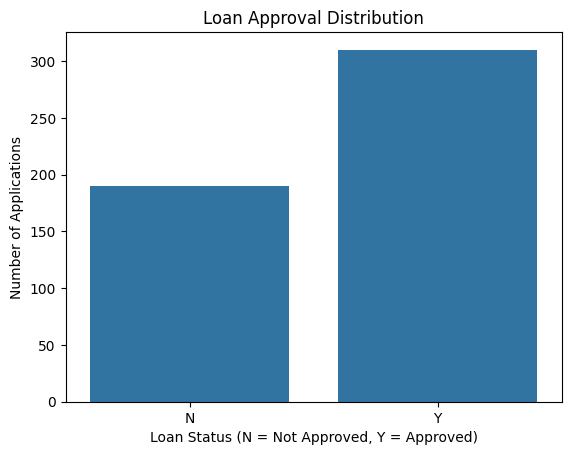

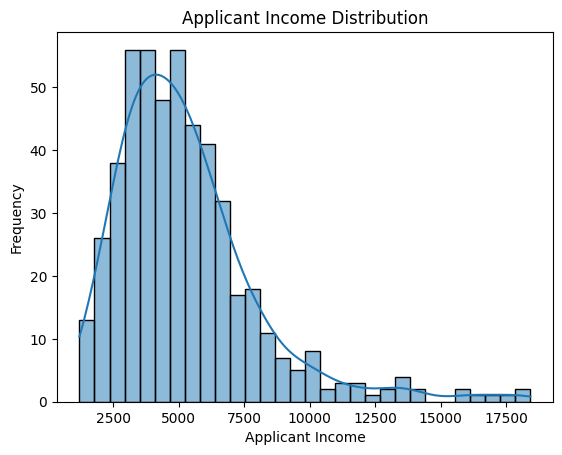

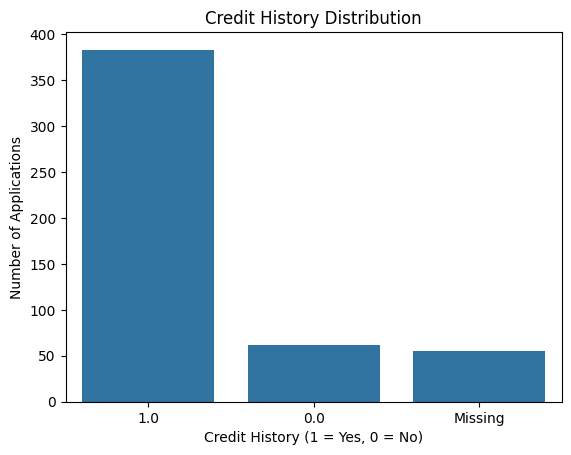

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Loan approval distribution
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (N = Not Approved, Y = Approved)")
plt.ylabel("Number of Applications")
plt.show()

# 2. Applicant income distribution
sns.histplot(data=df, x="ApplicantIncome", bins=30, kde=True)
plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")
plt.show()

# 3. Credit history distribution, including missing values
sns.countplot(
    x=df["Credit_History"].fillna("Missing").astype(str)
)
plt.title("Credit History Distribution")
plt.xlabel("Credit History (1 = Yes, 0 = No)")
plt.ylabel("Number of Applications")
plt.show()

In [4]:
# Summary statistics for important numerical columns
print(df[[
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]].describe())

# Check income and loan amount extremes
print("\nHighest applicant incomes:")
print(df.nlargest(5, "ApplicantIncome")[
    ["ApplicantIncome", "LoanAmount", "Loan_Status"]
])

print("\nHighest loan amounts:")
print(df.nlargest(5, "LoanAmount")[
    ["ApplicantIncome", "LoanAmount", "Loan_Status"]
])

       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term
count       500.000000         500.000000  490.000000        500.000000
mean       5262.320000        1786.046000  573.408163        314.880000
std        2731.103485        2157.717985   71.992904         71.531946
min        1200.000000           0.000000  191.000000        120.000000
25%        3418.500000           0.000000  600.000000        300.000000
50%        4783.500000        1161.000000  600.000000        360.000000
75%        6315.000000        2720.250000  600.000000        360.000000
max       18426.000000       12000.000000  600.000000        360.000000

Highest applicant incomes:
     ApplicantIncome  LoanAmount Loan_Status
98             18426       600.0           N
211            18035       600.0           Y
381            17647       600.0           Y
187            17118       600.0           Y
490            16313       600.0           Y

Highest loan amounts:
    ApplicantIncome  LoanAmount

In [5]:
print("Loan amounts equal to 600:")
print((df["LoanAmount"] == 600).sum())

print("\nLoan amount value counts:")
print(df["LoanAmount"].value_counts().head(10))

print("\nLoan amount percentiles:")
print(df["LoanAmount"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

Loan amounts equal to 600:
404

Loan amount value counts:
LoanAmount
600.0    404
436.0      2
570.0      2
429.0      2
494.0      2
563.0      2
598.0      2
498.0      2
378.0      2
411.0      1
Name: count, dtype: int64

Loan amount percentiles:
0.25    600.0
0.50    600.0
0.75    600.0
0.90    600.0
0.95    600.0
0.99    600.0
Name: LoanAmount, dtype: float64


In [7]:
import pandas as pd

# Load the public training dataset
df_public = pd.read_csv(
    "../data/raw/loan_applications_public.csv"
)

print("Dataset shape:", df_public.shape)

print("\nFirst 5 rows:")
display(df_public.head())

print("\nColumn names:")
print(df_public.columns.tolist())

print("\nMissing values:")
print(df_public.isnull().sum())

print("\nDuplicate rows:", df_public.duplicated().sum())

print("\nLoan status distribution:")
print(df_public["Loan_Status"].value_counts(dropna=False))

print("\nLoan amount summary:")
print(df_public["LoanAmount"].describe())

Dataset shape: (367, 12)

First 5 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban



Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Missing values:
Loan_ID               0
Gender               11
Married               0
Dependents           10
Education             0
Self_Employed        23
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            5
Loan_Amount_Term      6
Credit_History       29
Property_Area         0
dtype: int64

Duplicate rows: 0

Loan status distribution:


KeyError: 'Loan_Status'

In [1]:
import pandas as pd

train_df = pd.read_csv("../data/raw/loan_applications_public.csv")
test_df = pd.read_csv("../data/raw/loan_applications_test.csv")

print("Public file columns:")
print(train_df.columns.tolist())

print("\nTest file columns:")
print(test_df.columns.tolist())

print("\nDoes public file contain Loan_Status?")
print("Loan_Status" in train_df.columns)

print("\nDoes test file contain Loan_Status?")
print("Loan_Status" in test_df.columns)

Public file columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Test file columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Does public file contain Loan_Status?
False

Does test file contain Loan_Status?
True


In [2]:
train_df = pd.read_csv("../data/raw/loan_applications_public.csv")
test_df = pd.read_csv("../data/raw/loan_applications_test.csv")

print("Training dataset:", train_df.shape)
print("Training target exists:", "Loan_Status" in train_df.columns)

print("Test dataset:", test_df.shape)
print("Test target exists:", "Loan_Status" in test_df.columns)

Training dataset: (614, 13)
Training target exists: True
Test dataset: (367, 12)
Test target exists: False


In [3]:
# 1. Dataset dimensions
print("Shape:", train_df.shape)

# 2. Target distribution
print("\nLoan status counts:")
print(train_df["Loan_Status"].value_counts())

print("\nLoan status percentages:")
print(
    (train_df["Loan_Status"].value_counts(normalize=True) * 100)
    .round(2)
)

# 3. Missing values
print("\nMissing values:")
print(train_df.isnull().sum())

# 4. Loan amount summary
print("\nLoan amount summary:")
print(train_df["LoanAmount"].describe())

# 5. Duplicate rows
print("\nDuplicate rows:", train_df.duplicated().sum())

Shape: (614, 13)

Loan status counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan status percentages:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Loan amount summary:
count    592.000000
mean     146.412162
std       85.587325
min        9.000000
25%      100.000000
50%      128.000000
75%      168.000000
max      700.000000
Name: LoanAmount, dtype: float64

Duplicate rows: 0


In [4]:
# Categorical columns: inspect available values
categorical_columns = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area",
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(train_df[col].value_counts(dropna=False))

# Numerical columns: inspect summary statistics
numerical_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
]

print("\nNumerical feature summary:")
display(train_df[numerical_columns].describe())


Gender:
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64

Married:
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Dependents:
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

Education:
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

Self_Employed:
Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64

Property_Area:
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

Numerical feature summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
# Check the most extreme income values
print("Highest applicant incomes:")
display(
    train_df.nlargest(10, "ApplicantIncome")[
        ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Status"]
    ]
)

print("\nHighest co-applicant incomes:")
display(
    train_df.nlargest(10, "CoapplicantIncome")[
        ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Status"]
    ]
)

# Check all observed loan tenure categories
print("\nLoan tenure counts:")
print(train_df["Loan_Amount_Term"].value_counts(dropna=False).sort_index())


print(
    train_df["Loan_Amount_Term"]
    .value_counts(dropna=False)
    .sort_index()
)

Highest applicant incomes:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Status
409,81000,0.0,360.0,N
333,63337,0.0,490.0,Y
171,51763,0.0,700.0,Y
155,39999,0.0,600.0,Y
185,39147,4750.0,120.0,Y
443,37719,0.0,152.0,Y
183,33846,0.0,260.0,N
126,23803,0.0,370.0,Y
506,20833,6667.0,480.0,Y
284,20667,0.0,NaN,N



Highest co-applicant incomes:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Status
600,416,41667.0,350.0,N
581,1836,33837.0,90.0,N
402,2500,20000.0,103.0,Y
417,1600,20000.0,239.0,N
177,5516,11300.0,495.0,N
9,12841,10968.0,349.0,N
122,2137,8980.0,137.0,Y
444,7333,8333.0,175.0,Y
12,3073,8106.0,200.0,Y
372,9323,7873.0,380.0,Y



Loan tenure counts:
Loan_Amount_Term
12.0       1
36.0       2
60.0       2
84.0       4
120.0      3
180.0     44
240.0      4
300.0     13
360.0    512
480.0     15
NaN       14
Name: count, dtype: int64


In [7]:
# Separate input features and target

X = train_df.drop(columns=["Loan_Status", "Loan_ID"])
y = train_df["Loan_Status"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget labels:")
print(y.value_counts())

Feature matrix shape: (614, 11)
Target vector shape: (614,)

Feature columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target labels:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [8]:
# Identify categorical and numerical features

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal features:", len(categorical_features) + len(numerical_features))

Categorical features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

Numerical features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Total features: 11


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True).round(3))


Training features: (491, 11)
Validation features: (123, 11)

Training target distribution:
Loan_Status
Y    337
N    154
Name: count, dtype: int64
Loan_Status
Y    0.686
N    0.314
Name: proportion, dtype: float64

Validation target distribution:
Loan_Status
Y    85
N    38
Name: count, dtype: int64
Loan_Status
Y    0.691
N    0.309
Name: proportion, dtype: float64


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Handle missing values in categorical features
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Handle missing values in numerical features
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))


Preprocessing pipeline created successfully.
Categorical features: 6
Numerical features: 5


In [11]:

# Learn preprocessing rules from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same learned rules to validation data
X_val_processed = preprocessor.transform(X_val)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", X_train_processed.nnz if hasattr(X_train_processed, "nnz")
      else "Dense array — check with NumPy")


Original training shape: (491, 11)
Processed training shape: (491, 20)

Original validation shape: (123, 11)
Processed validation shape: (123, 20)

Missing values after preprocessing:
Training: Dense array — check with NumPy


In [12]:

import numpy as np

print("Training data contains NaN:", np.isnan(X_train_processed).any())
print("Validation data contains NaN:", np.isnan(X_val_processed).any())

print("\nTraining data contains infinity:",
      np.isinf(X_train_processed).any())

print("Validation data contains infinity:",
      np.isinf(X_val_processed).any())


Training data contains NaN: False
Validation data contains NaN: False

Training data contains infinity: False
Validation data contains infinity: False


In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and model
loan_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Train using the original training data
loan_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


c:\Users\GaneshG\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:

from sklearn.preprocessing import StandardScaler

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing now includes standardization.")



loan_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ]
)

loan_model.fit(X_train, y_train)

print("Model retrained with scaled numerical features.")


Numerical preprocessing now includes standardization.
Model retrained with scaled numerical features.


c:\Users\GaneshG\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

loan_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            solver="liblinear",
            max_iter=1000,
            random_state=42
        ))
    ]
)

loan_model.fit(X_train, y_train)

print("Model training completed.")

classifier = loan_model.named_steps["classifier"]
print("Solver:", classifier.solver)
print("Iterations used:", classifier.n_iter_)


Model training completed.
Solver: liblinear
Iterations used: [21]


In [16]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict loan outcomes for validation data
y_pred = loan_model.predict(X_val)

# Calculate accuracy
accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Accuracy (%): {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred, labels=["N", "Y"]))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=["N", "Y"],
        target_names=["Rejected (N)", "Approved (Y)"],
        zero_division=0
    )
)


Validation Accuracy: 0.8618
Validation Accuracy (%): 86.18%

Confusion Matrix:
[[22 16]
 [ 1 84]]

Classification Report:
              precision    recall  f1-score   support

Rejected (N)       0.96      0.58      0.72        38
Approved (Y)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [17]:

import pandas as pd

# Get predicted probabilities for validation applications
probabilities = loan_model.predict_proba(X_val)

# Identify which probability column corresponds to each class
classifier = loan_model.named_steps["classifier"]
classes = classifier.classes_

probability_df = pd.DataFrame(
    probabilities,
    columns=[f"Probability_{cls}" for cls in classes],
    index=X_val.index
)

probability_df["Actual_Status"] = y_val
probability_df["Predicted_Status"] = loan_model.predict(X_val)

print("Class order:", classes)
print("\nFirst 10 validation predictions:")
print(probability_df.head(10).round(3))

print("\nAverage predicted approval probability by actual status:")
print(
    probability_df.groupby("Actual_Status")["Probability_Y"]
    .mean()
    .round(3)
)


Class order: ['N' 'Y']

First 10 validation predictions:
     Probability_N  Probability_Y Actual_Status Predicted_Status
150          0.909          0.091             N                N
559          0.114          0.886             Y                Y
598          0.251          0.749             Y                Y
235          0.296          0.704             Y                Y
145          0.121          0.879             Y                Y
191          0.199          0.801             N                Y
557          0.123          0.877             Y                Y
470          0.191          0.809             Y                Y
88           0.307          0.693             Y                Y
386          0.281          0.719             Y                Y

Average predicted approval probability by actual status:
Actual_Status
N    0.402
Y    0.782
Name: Probability_Y, dtype: float64


In [18]:

from sklearn.metrics import confusion_matrix

approval_prob = probability_df["Probability_Y"].to_numpy()

for threshold in [0.40, 0.50, 0.60, 0.70]:
    predictions = np.where(approval_prob >= threshold, "Y", "N")

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=["N", "Y"]
    ).ravel()

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Correct rejections: {tn}")
    print(f"False approvals:    {fp}")
    print(f"False rejections:   {fn}")
    print(f"Correct approvals:  {tp}")



Threshold: 0.40
Correct rejections: 22
False approvals:    16
False rejections:   1
Correct approvals:  84

Threshold: 0.50
Correct rejections: 22
False approvals:    16
False rejections:   1
Correct approvals:  84

Threshold: 0.60
Correct rejections: 25
False approvals:    13
False rejections:   4
Correct approvals:  81

Threshold: 0.70
Correct rejections: 27
False approvals:    11
False rejections:   14
Correct approvals:  71


In [19]:

from sklearn.metrics import accuracy_score, precision_score, recall_score

approval_prob = probability_df["Probability_Y"].to_numpy()

for threshold in [0.40, 0.50, 0.60, 0.70]:
    predictions = np.where(approval_prob >= threshold, "Y", "N")

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Accuracy: {accuracy_score(y_val, predictions):.3f}")
    print(
        f"Approval precision: "
        f"{precision_score(y_val, predictions, pos_label='Y', zero_division=0):.3f}"
    )
    print(
        f"Approval recall: "
        f"{recall_score(y_val, predictions, pos_label='Y', zero_division=0):.3f}"
    )
    print(
        f"Rejection recall: "
        f"{recall_score(y_val, predictions, pos_label='N', zero_division=0):.3f}"
    )



Threshold: 0.40
Accuracy: 0.862
Approval precision: 0.840
Approval recall: 0.988
Rejection recall: 0.579

Threshold: 0.50
Accuracy: 0.862
Approval precision: 0.840
Approval recall: 0.988
Rejection recall: 0.579

Threshold: 0.60
Accuracy: 0.862
Approval precision: 0.862
Approval recall: 0.953
Rejection recall: 0.658

Threshold: 0.70
Accuracy: 0.797
Approval precision: 0.866
Approval recall: 0.835
Rejection recall: 0.711


In [20]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Baseline model: always predict the most frequent training class
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

baseline_predictions = dummy_model.predict(X_val)
logistic_predictions = loan_model.predict(X_val)

print("Majority-class baseline accuracy:",
      round(accuracy_score(y_val, baseline_predictions), 4))

print("Logistic Regression accuracy:",
      round(accuracy_score(y_val, logistic_predictions), 4))

print("\nBaseline classification report:")
print(classification_report(
    y_val,
    baseline_predictions,
    labels=["N", "Y"],
    target_names=["Rejected (N)", "Approved (Y)"],
    zero_division=0
))


Majority-class baseline accuracy: 0.6911
Logistic Regression accuracy: 0.8618

Baseline classification report:
              precision    recall  f1-score   support

Rejected (N)       0.00      0.00      0.00        38
Approved (Y)       0.69      1.00      0.82        85

    accuracy                           0.69       123
   macro avg       0.35      0.50      0.41       123
weighted avg       0.48      0.69      0.56       123



In [21]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Build a fresh pipeline for cross-validation
cv_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            solver="liblinear",
            max_iter=1000,
            random_state=42
        ))
    ]
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} ± {scores.std():.3f}"
    )


Accuracy: 0.796 ± 0.043
Precision: 0.827 ± 0.071
Recall: 0.690 ± 0.061
F1: 0.707 ± 0.077


In [22]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=10,
            random_state=42
        ))
    ]
)

tree_results = cross_validate(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("Decision Tree — 5-fold cross-validation\n")

for metric in scoring:
    scores = tree_results[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} ± {scores.std():.3f}"
    )


Decision Tree — 5-fold cross-validation

Accuracy: 0.762 ± 0.060
Precision: 0.756 ± 0.101
Recall: 0.677 ± 0.064
F1: 0.687 ± 0.076


In [23]:
from sklearn.metrics import accuracy_score, f1_score

# Train the Decision Tree on training data
tree_model.fit(X_train, y_train)

# Generate predictions on the same validation set
tree_predictions = tree_model.predict(X_val)
logistic_predictions = loan_model.predict(X_val)

# Compare validation performance
print("Validation Set Comparison\n")

print(
    "Logistic Regression Accuracy:",
    round(accuracy_score(y_val, logistic_predictions), 3)
)

print(
    "Decision Tree Accuracy:",
    round(accuracy_score(y_val, tree_predictions), 3)
)

print(
    "Logistic Regression Macro F1:",
    round(f1_score(y_val, logistic_predictions, average="macro"), 3)
)

print(
    "Decision Tree Macro F1:",
    round(f1_score(y_val, tree_predictions, average="macro"), 3)
)

Validation Set Comparison

Logistic Regression Accuracy: 0.862
Decision Tree Accuracy: 0.821
Logistic Regression Macro F1: 0.815
Decision Tree Macro F1: 0.772


In [24]:
from sklearn.metrics import confusion_matrix, classification_report

# Logistic Regression
logistic_predictions = loan_model.predict(X_val)

print("=== Logistic Regression ===")
print("Confusion Matrix (rows = actual, columns = predicted)")
print(confusion_matrix(y_val, logistic_predictions, labels=["N", "Y"]))
print("\nClassification Report")
print(classification_report(
    y_val,
    logistic_predictions,
    labels=["N", "Y"],
    target_names=["Rejected (N)", "Approved (Y)"],
    zero_division=0
))

# Decision Tree
print("\n=== Decision Tree ===")
print("Confusion Matrix (rows = actual, columns = predicted)")
print(confusion_matrix(y_val, tree_predictions, labels=["N", "Y"]))
print("\nClassification Report")
print(classification_report(
    y_val,
    tree_predictions,
    labels=["N", "Y"],
    target_names=["Rejected (N)", "Approved (Y)"],
    zero_division=0
))

=== Logistic Regression ===
Confusion Matrix (rows = actual, columns = predicted)
[[22 16]
 [ 1 84]]

Classification Report
              precision    recall  f1-score   support

Rejected (N)       0.96      0.58      0.72        38
Approved (Y)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


=== Decision Tree ===
Confusion Matrix (rows = actual, columns = predicted)
[[22 16]
 [ 6 79]]

Classification Report
              precision    recall  f1-score   support

Rejected (N)       0.79      0.58      0.67        38
Approved (Y)       0.83      0.93      0.88        85

    accuracy                           0.82       123
   macro avg       0.81      0.75      0.77       123
weighted avg       0.82      0.82      0.81       123



In [25]:
from sklearn.metrics import roc_auc_score

# Probability of the positive class: Loan_Status = "Y"
logistic_probabilities = loan_model.predict_proba(X_val)[
    :, list(loan_model.classes_).index("Y")
]

tree_probabilities = tree_model.predict_proba(X_val)[
    :, list(tree_model.classes_).index("Y")
]

# Convert target labels into binary values
y_val_binary = (y_val == "Y").astype(int)

print("ROC-AUC Comparison")
print(
    "Logistic Regression:",
    round(roc_auc_score(y_val_binary, logistic_probabilities), 3)
)
print(
    "Decision Tree:",
    round(roc_auc_score(y_val_binary, tree_probabilities), 3)
)

ROC-AUC Comparison
Logistic Regression: 0.856
Decision Tree: 0.773


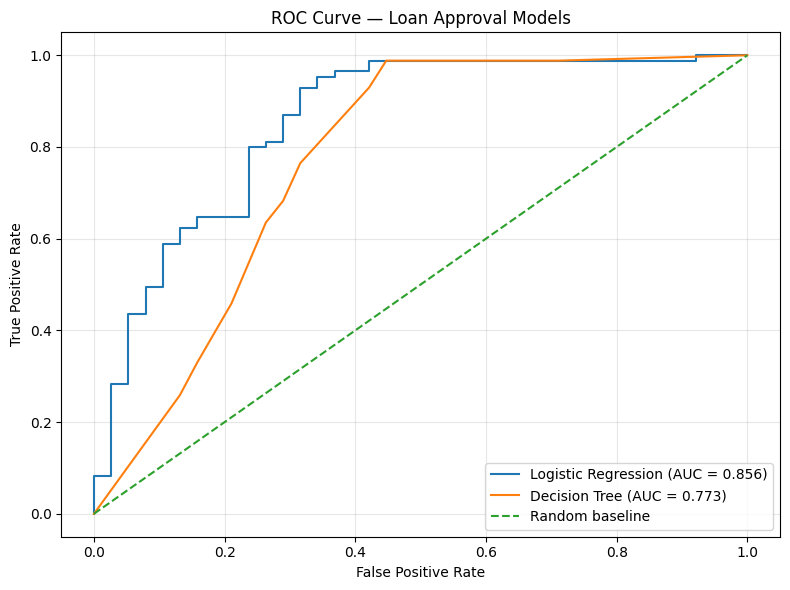

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ROC curve data
fpr_log, tpr_log, _ = roc_curve(
    y_val_binary, logistic_probabilities
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_val_binary, tree_probabilities
)

auc_log = roc_auc_score(y_val_binary, logistic_probabilities)
auc_tree = roc_auc_score(y_val_binary, tree_probabilities)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log, tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.3f})"
)

plt.plot(
    fpr_tree, tpr_tree,
    label=f"Decision Tree (AUC = {auc_tree:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Loan Approval Models")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
import pandas as pd
import numpy as np

# Get the fitted preprocessing and classifier steps
fitted_preprocessor = loan_model.named_steps["preprocessor"]
classifier = loan_model.named_steps["classifier"]

# Obtain feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = classifier.coef_[0]

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    by="Absolute_Importance",
    ascending=False
)

print("Top 10 Features by Absolute Coefficient")
print(importance_df.head(10).to_string(index=False))

Top 10 Features by Absolute Coefficient
                             Feature  Coefficient  Absolute_Importance
           numerical__Credit_History     3.001847             3.001847
           categorical__Dependents_1    -0.452144             0.452144
             categorical__Married_No    -0.441755             0.441755
    categorical__Property_Area_Rural    -0.409788             0.409788
 categorical__Education_Not Graduate    -0.367981             0.367981
categorical__Property_Area_Semiurban     0.320982             0.320982
            categorical__Gender_Male    -0.280177             0.280177
           categorical__Dependents_2     0.265193             0.265193
    categorical__Property_Area_Urban    -0.241784             0.241784
      categorical__Self_Employed_Yes    -0.223507             0.223507


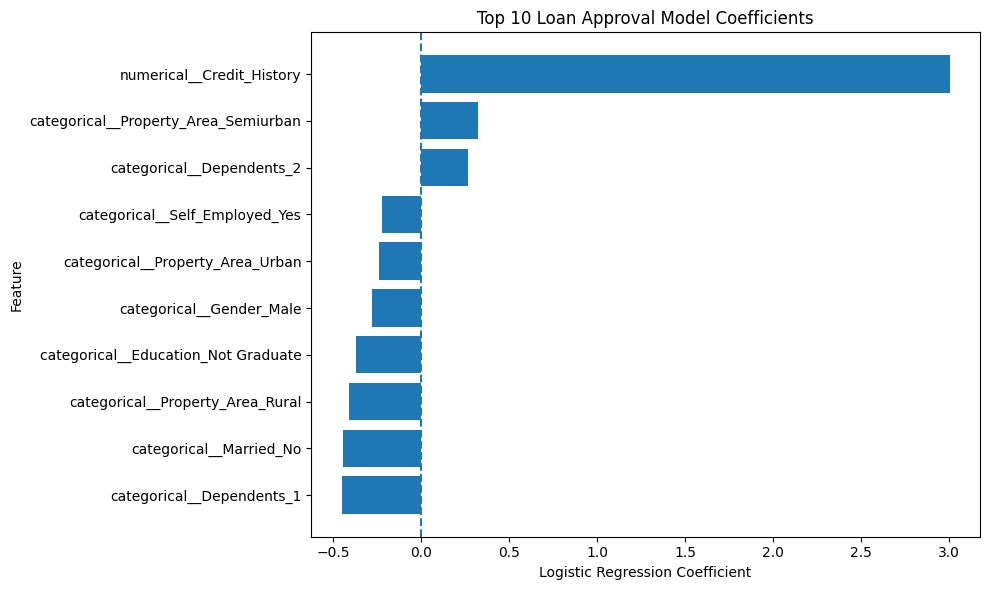

In [28]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Loan Approval Model Coefficients")
plt.tight_layout()
plt.show()

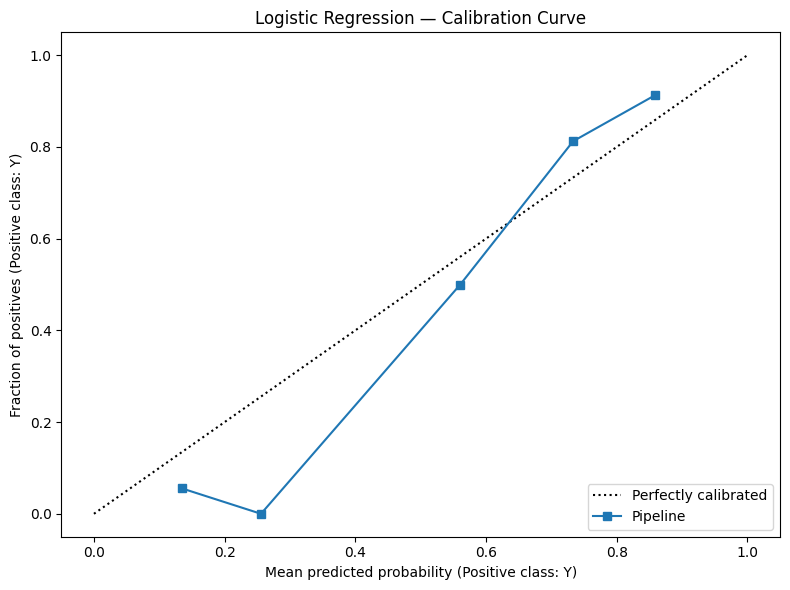

In [29]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_estimator(
    loan_model,
    X_val,
    y_val,
    pos_label="Y",
    n_bins=5,
    strategy="uniform",
    ax=ax
)

ax.set_title("Logistic Regression — Calibration Curve")
plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path
import joblib

# Create the model artifacts directory
artifacts_dir = Path("../artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Save the complete fitted pipeline
model_path = artifacts_dir / "loan_approval_logistic_regression.joblib"

joblib.dump(loan_model, model_path)

print("Model saved successfully!")
print("Saved to:", model_path.resolve())
print("Model type:", type(loan_model).__name__)

Model saved successfully!
Saved to: D:\loan-approval-recommendation\artifacts\loan_approval_logistic_regression.joblib
Model type: Pipeline


In [31]:
import joblib
from pathlib import Path

model_path = Path("../artifacts/loan_approval_logistic_regression.joblib")

# Load the saved pipeline
loaded_model = joblib.load(model_path)

# Predict one application from the validation set
sample = X_val.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
probabilities = loaded_model.predict_proba(sample)[0]

print("Model loaded successfully!")
print("Predicted status:", prediction)
print("Approval probability:", round(
    probabilities[list(loaded_model.classes_).index("Y")], 3
))

Model loaded successfully!
Predicted status: N
Approval probability: 0.091
